# CSCN8000 – Lab 2: Probability, Naive Bayes and Outlier Detection
**Student:** Zeynep Ozdemir  |  **Student ID:** 9045142
**Date:** 23-10-2026
 
**Objectives:** Compare GaussianNB and MultinomialNB for spam detection;
examine NYC Airbnb prices and create several cleaned datasets.


## Importing Required Libraries

I imported the required Python libraries for data preprocessing, visualization, machine learning, and model evaluation.

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import MinMaxScaler
 
sns.set_theme(style="whitegrid")
DATA = Path("data")
print("CSV files:", [x.name for x in DATA.glob("*.csv")])


CSV files: ['AB_NYC_2019.csv', 'lab2_spam.csv']


# Part A — load and inspect the spam data

I loaded the spam dataset and checked its shape, columns, and missing values by using basic eda. I selected the `label` and `text` columns and renamed `text` to `message`.

I standardized the labels by removing extra spaces and converting them to lowercase. Finally, I converted the labels into numerical values, where ham = 0 and spam = 1, to prepare the dataset for machine learning.

In [15]:
SPAM_FILE = DATA / "lab2_spam.csv"  # CHANGE THIS
spam_df = pd.read_csv(SPAM_FILE, encoding="latin-1")
print("Shape:", spam_df.shape)
print("Columns:", spam_df.columns.tolist())
display(spam_df.head())
print(spam_df.isna().sum())


# Select the correct columns
LABEL_COL = "label"
TEXT_COL = "text"

# Create a copy of the required columns
work = spam_df[[LABEL_COL, TEXT_COL]].copy()
work.columns = ["label", "message"]

# Remove missing values
work = work.dropna(subset=["label", "message"])

# Convert messages to strings
work["message"] = work["message"].astype(str)

# Clean the labels
work["label"] = work["label"].astype(str).str.strip().str.lower()

# Count spam and ham messages
print("Labels:", work["label"].value_counts())

# Check that there are exactly two classes
assert work["label"].nunique() == 2, "Expected 2 classes"

# Convert labels to numerical values
if set(work["label"].unique()) == {"spam", "ham"}:
    work["target"] = work["label"].map({"ham": 0, "spam": 1})
else:
    raise ValueError("Check your label values")

# Display the cleaned dataset
display(work.head())


Shape: (5171, 4)
Columns: ['Unnamed: 0', 'label', 'text', 'label_num']


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64
Labels: label
ham     3672
spam    1499
Name: count, dtype: int64


,label,message,target
0,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\nthis deal is to ...,0


# Part A — split, vectorize, train, evaluate

In this task, I split the data into 80% training and 20% testing. I used CountVectorizer to convert text into numerical values because machine learning algorithms work with numerical patterns to train and make predictions. After training GaussianNB and MultinomialNB, I evaluated both models using accuracy, precision, recall, F1-score, and confusion matrices. GaussianNB achieved 95% accuracy, while MultinomialNB achieved 98% accuracy. Therefore, I selected MultinomialNB because it had the highest accuracy.

,model,accuracy,precision_spam,recall_spam,f1_spam
1,MultinomialNB,0.9758,0.9693,0.9467,0.9578
0,GaussianNB,0.9546,0.9408,0.9000,0.9199


GaussianNB report:
               precision    recall  f1-score   support

           0       0.96      0.98      0.97       735
           1       0.94      0.90      0.92       300

    accuracy                           0.95      1035
   macro avg       0.95      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035

MultinomialNB report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.98       735
           1       0.97      0.95      0.96       300

    accuracy                           0.98      1035
   macro avg       0.97      0.97      0.97      1035
weighted avg       0.98      0.98      0.98      1035



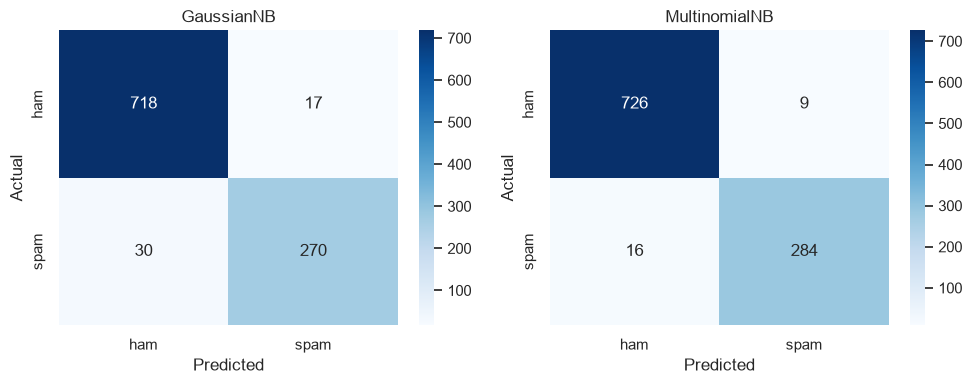

Best model by spam F1-score: MultinomialNB


,message,actual,gaussian_pred,multinomial_pred
294,Subject: account activated\nthank you for repl...,0,0,0
453,Subject: canvas\n2005 cable t v de 5 rambler w...,1,1,1
638,Subject: re : brandywine meter # : 981225 ; ma...,0,0,0
139,Subject: issues\nvalero has accepted this prop...,0,0,0
539,Subject: union carbide - safety net gas\nunion...,0,0,0
365,Subject: re : april spot tickets\nthe spot dea...,0,0,0
513,Subject: re : big cowboy for august\nmary :\ni...,0,0,0
584,"Subject: enron nominations for november 8 , 20...",0,0,0
231,Subject: re : txu fuel deals imbalances\ni ' m...,0,0,0
210,Subject: nesa / hea ' s 9 th annual crawfish b...,0,0,0


In [16]:
# Step 1: Split the dataset (80% training, 20% testing)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    work["message"],
    work["target"],
    test_size=0.20,
    random_state=42,
    stratify=work["target"]
)

# Step 2: Convert text into word counts
vectorizer = CountVectorizer(stop_words="english")
X_train_counts = vectorizer.fit_transform(X_train_text)
X_test_counts = vectorizer.transform(X_test_text)

# Step 3: Train MultinomialNB
multi = MultinomialNB()
multi.fit(X_train_counts, y_train)
pred_multi = multi.predict(X_test_counts)

# Step 4: Train GaussianNB
# GaussianNB requires dense arrays
X_train_dense = X_train_counts.toarray()
X_test_dense = X_test_counts.toarray()

gauss = GaussianNB()
gauss.fit(X_train_dense, y_train)
pred_gauss = gauss.predict(X_test_dense)

# Step 5: Evaluate both models
def score_row(name, actual, predicted):
    return {
        "model": name,
        "accuracy": accuracy_score(actual, predicted),
        "precision_spam": precision_score(actual, predicted, zero_division=0),
        "recall_spam": recall_score(actual, predicted, zero_division=0),
        "f1_spam": f1_score(actual, predicted, zero_division=0)
    }

results = pd.DataFrame([
    score_row("GaussianNB", y_test, pred_gauss),
    score_row("MultinomialNB", y_test, pred_multi)
]).sort_values("f1_spam", ascending=False)

display(results.round(4))

# Step 6: Classification reports
print("GaussianNB report:\n", classification_report(y_test, pred_gauss))
print("MultinomialNB report:\n", classification_report(y_test, pred_multi))

# Step 7: Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name, preds in zip(
    axes,
    ["GaussianNB", "MultinomialNB"],
    [pred_gauss, pred_multi]
):
    cm = confusion_matrix(y_test, preds, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"]
    )

    ax.set(title=name, xlabel="Predicted", ylabel="Actual")

plt.tight_layout()
plt.show()

# Step 8: Find the best model
best_name = results.iloc[0]["model"]
print("Best model by spam F1-score:", best_name)

# Step 9: Display sample predictions
predictions = pd.DataFrame({
    "message": X_test_text.to_numpy(),
    "actual": y_test.to_numpy(),
    "gaussian_pred": pred_gauss,
    "multinomial_pred": pred_multi
})

display(predictions.sample(min(10, len(predictions)), random_state=42))

# Part A — use the trained model for new predictions

I entered new text to make predictions using the trained model

In [17]:
examples = [
    "Congratulations Zeynep! Claim your free cash prize now",
    "Hi Professor, are we still meeting at 3 pm today?",
    "URGENT: click this link to verify your account"
]
examples_counts = vectorizer.transform(examples)
chosen_predictions = (multi.predict(examples_counts)
                      if best_name == "MultinomialNB"
                      else gauss.predict(examples_counts.toarray()))
for text, label in zip(examples, chosen_predictions):
    print(f"{'spam' if label == 1 else 'ham'}: {text}")


spam: Congratulations Zeynep! Claim your free cash prize now
ham: Hi Professor, are we still meeting at 3 pm today?
spam: URGENT: click this link to verify your account


# Part B — load and inspect New York City Airbnb prices
First, we load the Airbnb data and do basic EDA. Then, we clean the price column by removing invalid values. Next, we use graphs to show the nightly prices. The graphs show that the prices are right-skewed, meaning most prices are low, but a few are very high. Finally, we calculate statistics like mean, median, and standard deviation.

Shape: (48895, 16)
Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
1%          30.000000
5%          40.000000
25%         69.000000
50%        106.000000
75%        175.000000
95%        355.000000
99%        799.000000
max      10000.000000
Name: price, dtype: float64
Missing prices: 0
Nonpositive prices: 11
Usable rows: 48884


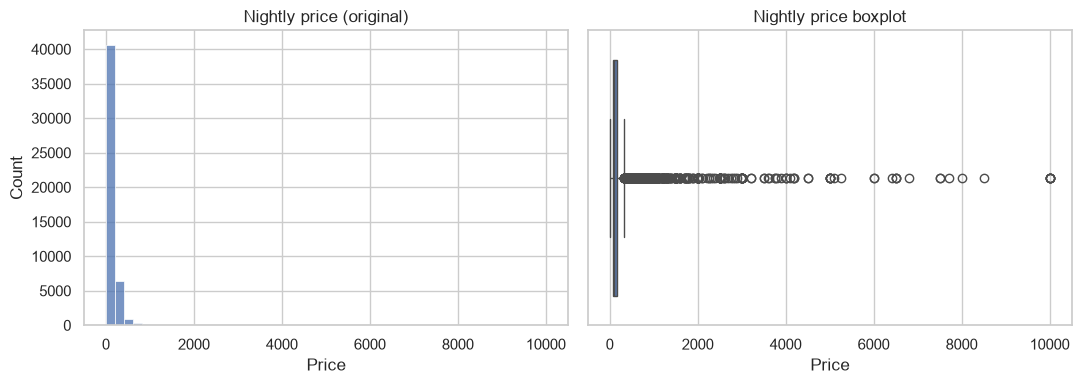

Mean: 152.75505277800508 Median: 106.0 Standard deviation: 240.17026010903956


In [18]:
AIRBNB_FILE = DATA / "AB_NYC_2019.csv"  # CHANGE THIS
bnb = pd.read_csv(AIRBNB_FILE)
print("Shape:", bnb.shape)
print("Columns:", bnb.columns.tolist())
display(bnb.head())
 
PRICE_COL = "price"  # CHANGE if the actual column differs
bnb[PRICE_COL] = pd.to_numeric(
    bnb[PRICE_COL].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce")
print(bnb[PRICE_COL].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))
print("Missing prices:", bnb[PRICE_COL].isna().sum())
print("Nonpositive prices:", (bnb[PRICE_COL] <= 0).sum())
 
# Remove missing and implausible zero/negative prices first.
base = bnb.loc[bnb[PRICE_COL].notna() & (bnb[PRICE_COL] > 0)].copy()
print("Usable rows:", len(base))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(base[PRICE_COL], bins=50, ax=axes[0])
axes[0].set(title="Nightly price (original)", xlabel="Price")
sns.boxplot(x=base[PRICE_COL], ax=axes[1])
axes[1].set(title="Nightly price boxplot", xlabel="Price")
plt.tight_layout()
plt.show()
print("Mean:", base[PRICE_COL].mean(),
      "Median:", base[PRICE_COL].median(),
      "Standard deviation:", base[PRICE_COL].std())


# Part B — compare several outlier methods
I performed **outlier detection and data cleaning** on my Airbnb NYC dataset using four statistical methods: IQR, Percentile Trimming, Z-score, and MAD. I compared how each method affected the data using summary statistics and boxplots. After selecting IQR, I validated the cleaned dataset and saved it as a CSV file with 45,912 rows. I also tested Groupwise IQR to identify unusual prices within each room type separately. This helped me understand how different cleaning methods affect data quality and why choosing the right approach depends on the dataset.

## IQR (quartiles): recommended robust baseline

In [19]:
q1, q3 = base[PRICE_COL].quantile([0.25, 0.75])

iqr = q3 - q1

low_iqr = q1 - 1.5 * iqr
high_iqr = q3 + 1.5 * iqr

clean_iqr = base[
    base[PRICE_COL].between(low_iqr, high_iqr)
].copy()

print("Original rows:", len(base))
print("Cleaned rows:", len(clean_iqr))
print("Rows removed:", len(base) - len(clean_iqr))

Original rows: 48884
Cleaned rows: 45912
Rows removed: 2972


## Percentile trimming

In [20]:
low_pct, high_pct = base[PRICE_COL].quantile([0.01, 0.99])
clean_pct = base[base[PRICE_COL].between(low_pct, high_pct)].copy()
print("1%–99% bounds:", low_pct, high_pct, "rows kept:", len(clean_pct))

1%–99% bounds: 30.0 799.0 rows kept: 48017


## Mean ± 3 standard deviations (z-score)

In [21]:
mu, sigma = base[PRICE_COL].mean(), base[PRICE_COL].std()
if sigma > 0:
    z = (base[PRICE_COL] - mu) / sigma
    clean_z = base.loc[z.abs() <= 3].copy()
else:
    clean_z = base.copy()
print("Z-score rows kept:", len(clean_z))


Z-score rows kept: 48496


## Median absolute deviation (MAD)

In [22]:
median_price = base[PRICE_COL].median()
mad = (base[PRICE_COL] - median_price).abs().median()
if mad > 0:
    modified_z = 0.6745 * (base[PRICE_COL] - median_price) / mad
    clean_mad = base.loc[modified_z.abs() <= 3.5].copy()
else:
    clean_mad = base.copy()
print("MAD rows kept:", len(clean_mad))


MAD rows kept: 45968


## Compare, visualize and choose

,method,rows_kept,removed_from_valid,percent_removed,mean_price,median_price,max_price
0,Valid prices only,48884,0,0.00,152.76,106.0,10000
1,IQR,45912,2972,6.08,120.00,100.0,334
2,1–99 percentile,48017,867,1.77,138.50,105.0,799
3,Z-score (3 SD),48496,388,0.79,138.78,105.0,860
4,Modified Z (MAD),45968,2916,5.97,120.27,100.0,344


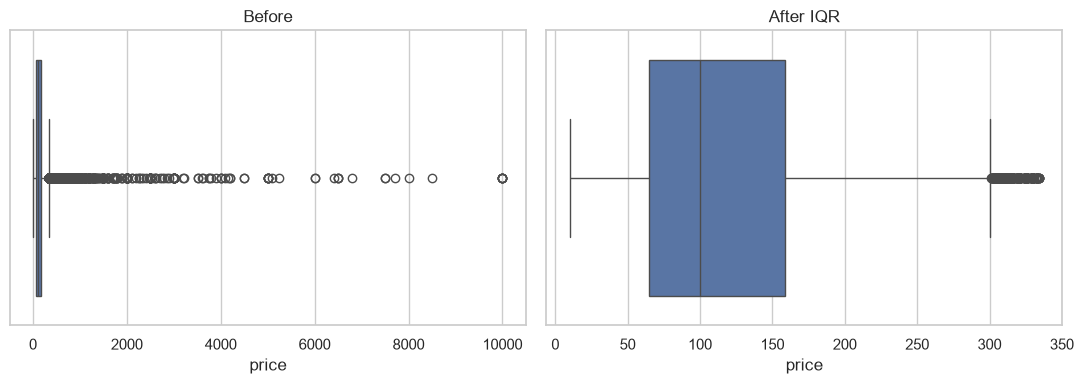

In [23]:
methods = {"Valid prices only": base, "IQR": clean_iqr,
           "1–99 percentile": clean_pct, "Z-score (3 SD)": clean_z,
           "Modified Z (MAD)": clean_mad}
comparison = pd.DataFrame([
    {"method": name, "rows_kept": len(frame),
     "removed_from_valid": len(base) - len(frame),
     "percent_removed": 100 * (len(base) - len(frame)) / len(base),
     "mean_price": frame[PRICE_COL].mean(),
     "median_price": frame[PRICE_COL].median(),
     "max_price": frame[PRICE_COL].max()}
    for name, frame in methods.items()])
display(comparison.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=base[PRICE_COL], ax=axes[0]); axes[0].set_title("Before")
sns.boxplot(x=clean_iqr[PRICE_COL], ax=axes[1]); axes[1].set_title("After IQR")
plt.tight_layout(); plt.show()


### Why I Chose IQR

I chose the IQR method because it is less affected by extreme prices than methods based on the mean. I also tried Groupwise IQR because different Airbnb room types have different price ranges, so comparing similar rooms makes more sense.

In [24]:
final_clean = clean_iqr.copy()  # choose your preferred method
assert final_clean[PRICE_COL].notna().all()
assert (final_clean[PRICE_COL] > 0).all()
assert final_clean[PRICE_COL].between(low_iqr, high_iqr).all()
final_clean.to_csv("airbnb_nyc_cleaned.csv", index=False)
print("Saved cleaned dataset:", final_clean.shape)
display(final_clean.head())


Saved cleaned dataset: (45912, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [25]:
if "room_type" in base.columns:
    def keep_group_iqr(group):
        a, b = group[PRICE_COL].quantile([0.25, 0.75])
        spread = b - a
        return group[group[PRICE_COL].between(a - 1.5*spread,
                                              b + 1.5*spread)]
    clean_by_room = pd.concat(
        [keep_group_iqr(g) for _, g in base.groupby("room_type")],
        axis=0).sort_index()
    print("Groupwise IQR rows kept:", len(clean_by_room))
else:
    print("room_type not provided; skip groupwise comparison")


Groupwise IQR rows kept: 45640


### Observation

I noticed that each method handled outliers differently. IQR and MAD removed more extreme prices, while Z-score kept more data. I also realized that Airbnb prices depend on the room type, so comparing similar rooms makes more sense. What I learned is that data cleaning isn't just about removing values. It's about understanding the data before deciding what to keep or remove.